# **Linear filters**
## Image Processing and Computer Vision


Linear filters are neighborhood operations (like local adaptive histogram equalization) which can perform local tone adjustment to add:
- soft blur
- sharp details
- accenture edges
- remove noise
- ...

In [2]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

## Box/Mean Filter

The Box (or Mean) filter is one of the most simplest operator:
- the box filter is a low-pass filter. That is, it attenuates the high spatial-frequency content of the input image.
- It blurs the image (simplification of the image)
- It reduces the noise
- The filter smooth the details and cancels out small-size details
- It could produce artifacts over the image when the kernel size is large

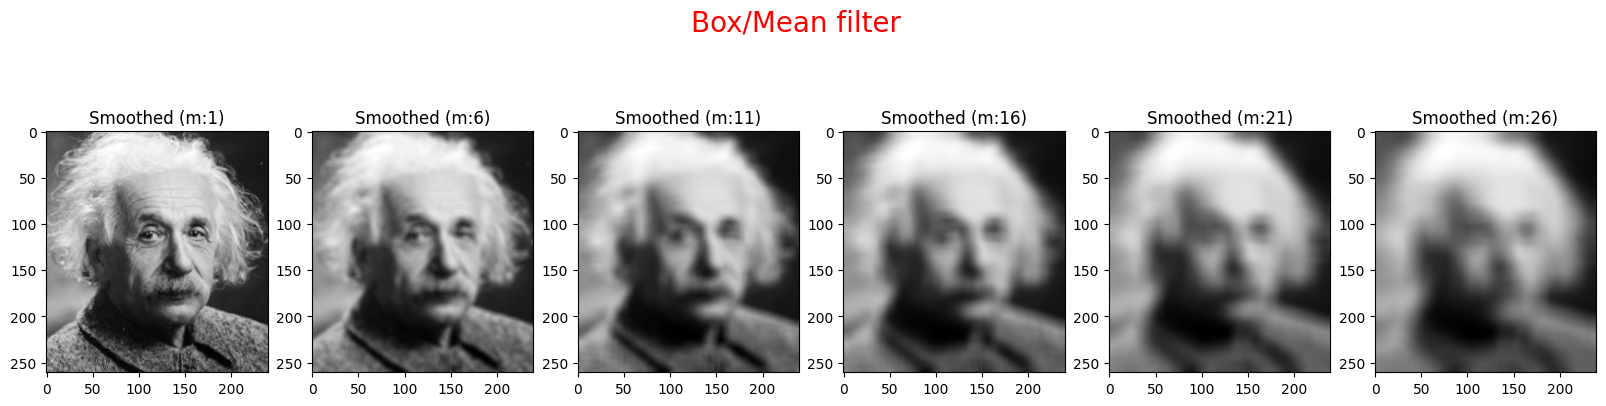

In [ ]:
IMG_PATH = "img/Einstein.png"
img  = cv2.imread(IMG_PATH, cv2.IMREAD_GRAYSCALE)
smoothed_imgs = [(cv2.boxFilter(img, -1, (m,m), normalize = True), m) for m in range(1,30,5)]
n = len(smoothed_imgs)

plt.figure(figsize=(20, 5))
plt.suptitle("Box/Mean filter", fontsize = 20, color = "red")

plt.subplot(1,n,1)
plt.imshow(img, cmap="gray")
plt.title("Original img")

for i, imgs in enumerate(smoothed_imgs):
    img, m  = imgs
    plt.subplot(1,n,i + 1)
    plt.imshow(img, cmap="gray")
    plt.title(f"Smoothed (m:{m})")



## Gaussian Filter

The gaussian addresses some issues of the box filter:
- It is a blurring low-pass filter so it reduces the high-frequency noise.
- The convolution of two n-dimensional Gaussians is an n-dimensional Gaussian.
- We can compute efficiently the operation by applying separability property: the 2D Gaussian can be decomposed into a product of 1D Gaussian

Considering that the interval [-3σ, +3σ] captures 99% of the area (“energy”) of the Gaussian function we can proceed to choose the correct size of the kernel according to σ using the rule-of-thumb: (2k + 1) x (2k + 1) kernel with k = ⌈3σ⌉

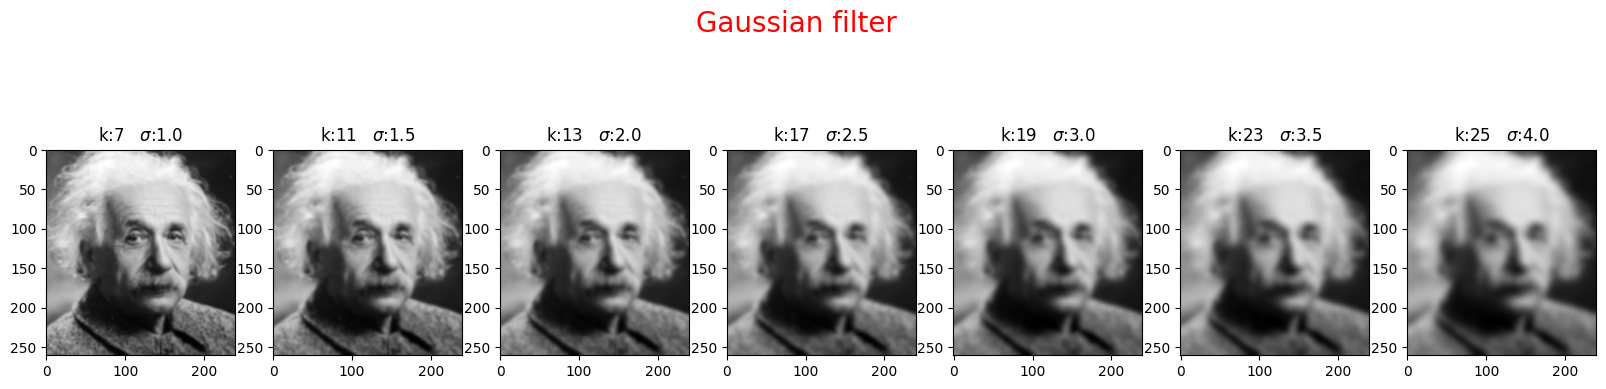

In [17]:
IMG_PATH = "img/Einstein.png"
img  = cv2.imread(IMG_PATH, cv2.IMREAD_GRAYSCALE)
filtered_imgs = [] 

for sigma in np.arange(1, 4.5, 0.5):
    k_size = int(np.ceil((3*sigma))*2 + 1) #rule of thumb for a good kernel size given sigma

    #Compute the denoising with the gaussian filter
    guass_img = cv2.GaussianBlur(img, (k_size,k_size) , sigma)

    filtered_imgs.append((guass_img, k_size, sigma))

n = len(filtered_imgs)

plt.figure(figsize=(20, 5))
plt.suptitle("Gaussian filter", fontsize = 20, color = "red")

plt.subplot(1,n,1)
plt.imshow(img, cmap="gray")
plt.title("Original img")

for i, imgs_data in enumerate(filtered_imgs):
    img, k_val, sigma_val  = imgs_data
    plt.subplot(1,n,i + 1)
    plt.imshow(img, cmap="gray")
    plt.title(f"k:{k_val}   $\\sigma$:{sigma_val}")

## Sharpening filters

We can exploit the smoothing kernels to sharpen images using unsharp masking. 
$$
g_{\text{sharp}} = f + \gamma\,\big(f - h_{\text{blur}} * f\big)
$$

where:
- $f$: the original input image.
- $h_{\text{blur}}$: a low-pass (blur) kernel, typically a Gaussian; its size/σ sets which details count as "high frequency".
- $*$: 2-D convolution.
- $h_{\text{blur}} * f$: the blurred image, i.e. the low-frequency content of $f$.
- $f - h_{\text{blur}} * f$: the **unsharp mask**, i.e. the high-frequency detail (edges, texture). It takes both positive and negative values.
- $\gamma \ge 0$: the sharpening gain (amount); $\gamma = 0$ returns $f$ unchanged, larger values give stronger sharpening.
- $g_{\text{sharp}}$: the sharpened output, the original with its detail amplified.

How this method works: look at a 1-D step edge. The blurred version is a soft ramp, so img − blur is negative just before the edge and positive just after. Adding it back makes the dark side darker and the bright side brighter, right at the transition. Your eye reads that stronger local contrast as sharpness.

In [23]:
def sharpen_filter(img: np.array, sigma: int, gamma: float = 1) -> np.array:
    
    # Rule of thumb for a good kernel size given sigma
    k_size = int(np.ceil((3*sigma))*2 + 1) 
    
    # Compute the denoising image with the gaussian filter (smooth filter)
    blurred = cv2.GaussianBlur(img, (k_size,k_size) , sigma)

    # np.int16 to avoid uint8 overflow/underflow.
    mask = img.astype(np.int16) - blurred
    
    return np.clip(np.round(img.astype(float)+ gamma * mask), 0, 255).astype(np.uint8)

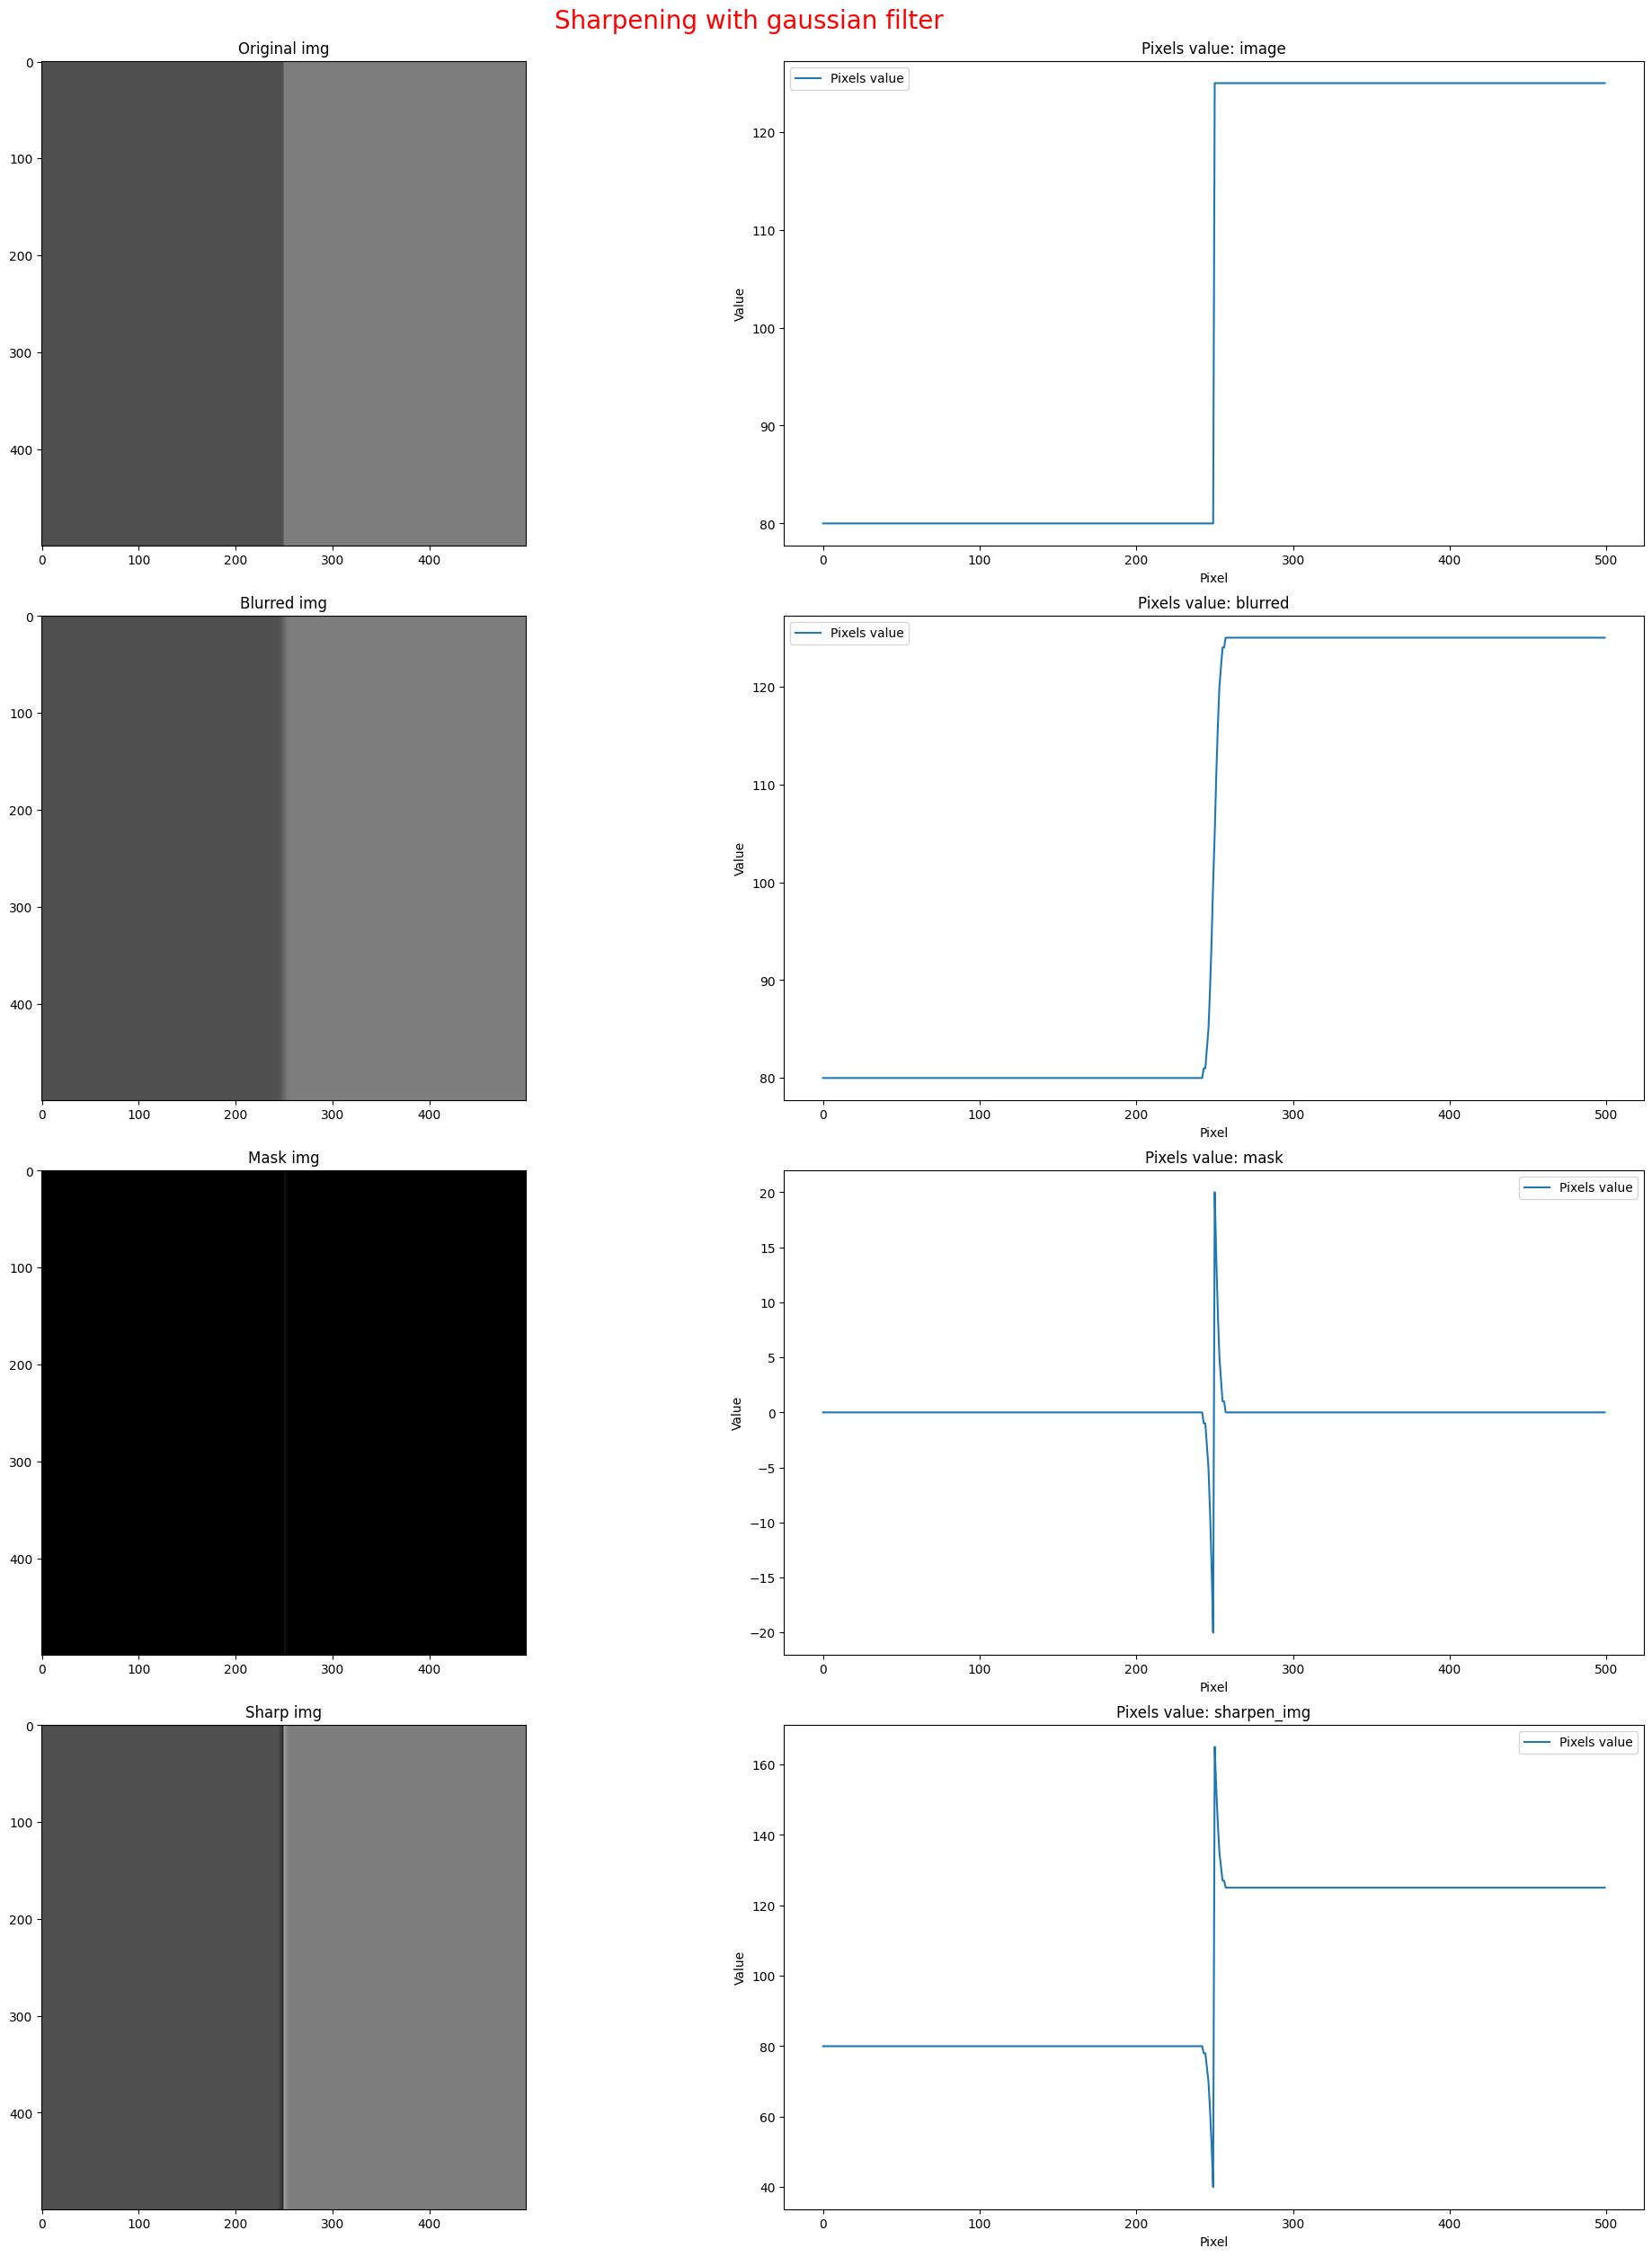

In [ ]:
# Generate an image with a vertical edge
img = np.empty((500, 500), dtype=np.uint8)
img[:,:250] = 80
img[:, 250:] = 125

# Extracted row to analyze
row = 0 

# Params sharpen filter
m = 5
gamma = 2
sigma = 3

# 1° step: use smoother filter
k_size = int(np.ceil((3*sigma))*2 + 1) #rule of thumb for a good kernel size given sigma
    
#Compute the denoising with the gaussian filter
blurred = cv2.GaussianBlur(img, (k_size,k_size) , sigma)

# 2° step: compute the mask
mask = img.astype(np.int16) - blurred

# 3° step: compute the sharpen image
sharpen_img = np.clip(np.round(img.astype(float)+ gamma * mask), 0, 255).astype(np.uint8)

plt.figure(figsize=(20, 25), layout="constrained")
plt.suptitle("Sharpening with gaussian filter", fontsize = 20, color = "red")

# Plot image
plt.subplot(4, 2, 1)
plt.imshow(img, cmap="gray", vmin = 0, vmax = 255)
plt.title("Original img")

plt.subplot(4, 2, 2)
plt.plot(img[row, :], label = "Pixels value", alpha = 1)
plt.title("Pixels value: image")
plt.xlabel("Pixel")
plt.ylabel("Value")
plt.legend()

# Plot blurred image
plt.subplot(4, 2, 3)
plt.imshow(blurred, cmap="gray", vmin = 0, vmax = 255)
plt.title(f"Blurred img")

plt.subplot(4, 2, 4)
plt.plot(blurred[row,:], label = "Pixels value", alpha = 1)
plt.title("Pixels value: blurred")
plt.xlabel("Pixel")
plt.ylabel("Value")
plt.legend()

# Plot mask
plt.subplot(4, 2, 5)
plt.imshow(mask, cmap="gray", vmin = 0, vmax = 255)
plt.title(f"Mask img")

plt.subplot(4, 2, 6)
plt.plot(mask[row,:], label = "Pixels value", alpha = 1)
plt.title("Pixels value: mask")
plt.xlabel("Pixel")
plt.ylabel("Value")
plt.legend()

# Plot sharpen filter
plt.subplot(4, 2, 7)
plt.imshow(sharpen_img, cmap="gray", vmin = 0, vmax = 255)
plt.title(f"Sharp img")

plt.subplot(4, 2, 8)
plt.plot(sharpen_img[row,:], label = "Pixels value", alpha = 1)
plt.title("Pixels value: sharpen_img")
plt.xlabel("Pixel")
plt.ylabel("Value")
plt.legend()



Example with a real image:

Text(0.5, 1.0, 'Sharp img')

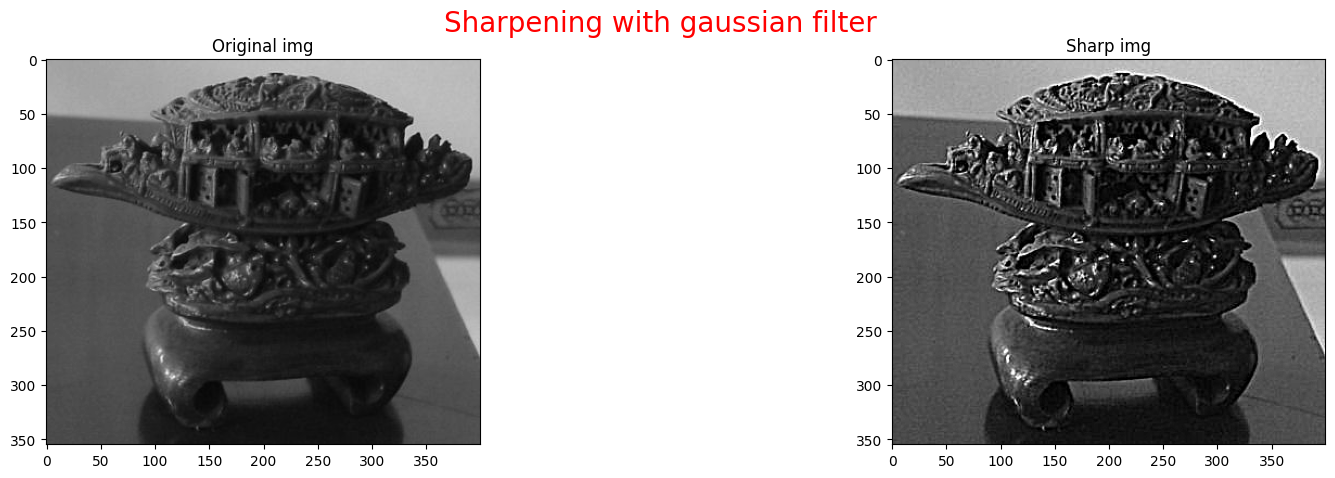

In [28]:
IMG_PATH = "img/kernel.png"
img  = cv2.imread(IMG_PATH, cv2.IMREAD_GRAYSCALE)
sharp_img = sharpen_filter(img, 2, 2)

plt.figure(figsize=(20, 5))
plt.suptitle("Sharpening with gaussian filter", fontsize = 20, color = "red")

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original img")


plt.subplot(1, 2, 2)
plt.imshow(sharp_img, cmap="gray")
plt.title(f"Sharp img")